# The six BCBS shocks step by step: the 0.417 scalar, the +25.4 bp steepener and the -1.6 bp flattener

**Question:** the standard turns three sizes per currency into six shapes of rate shock; how does each shape move the 19 bands of a dollar zero curve, how far did the 2024 recalibration move the rotations, and in which bands does a floor at zero stop the downward shocks?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (the 19 bands, the gap and the EVE)
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- build each of the six standard shock shapes (parallel up and down, short up and down, steepener, flattener) from its two scalars and its sizes, and read every intermediate;
- reproduce the standard's worked example (0.417, +41.7 bp, +25.4 bp and -1.6 bp at 3.5 years) with the engine and read the golden test that holds it;
- say where the sizes come from (the 2016 and the 2024 tables, and the table of the Chilean regulator), and what the engine does when a currency has no size;
- apply a post-shock floor and say which bands it binds in, with the zero floor and with the maturity-dependent floor of the European Union.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import shocks, slotting
from riskvalidation.validation import irrbb as rv_irrbb

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

Three committed documents feed the notebook:

- `data/derived/C14/vd-2022-q2.json` (case C14, the bank that failed in 2023 at 2022-06-30): the four scenario blocks with the six shock shapes in basis points at the 19 midpoints, the floors, the zero curve and the committed test rows. Sources: FDIC call reports and the US Treasury par curve, both `mirror-allowed`; real in aggregate, synthetic in behaviour.
- `data/derived/C14/models-svb-2021-2022.json`: the shock tables as fixtures (the 2016 calibration of BCBS d368 and the 2024 calibration in force from 2026-01-01) and the shape constants.
- `data/derived/C15/short-uf.json` (case C15, the synthetic Banco Andino on a CLP and UF balance sheet): the shock sizes of the Chilean regulator for the peso and the UF. Sources: the CMF (RAN 21-13 Annex 1) and the Banco Central de Chile curves, `mirror-allowed`; the bank is synthetic.

Shock sizes are in basis points. The next cell loads the three documents.

In [2]:
# Load the three documents (the notebook sits three folders below the repository root) and the 19 midpoints
ROOT = Path("../../..").resolve()
c14 = json.loads((ROOT / "data" / "derived" / "C14" / "vd-2022-q2.json").read_text(encoding="utf-8"))
c15 = json.loads((ROOT / "data" / "derived" / "C15" / "short-uf.json").read_text(encoding="utf-8"))
out14, out15 = c14["outputs"], c15["outputs"]
MID = slotting.bucket_grid().midpoints
LANG = "en"  # the bilingual fields of the documents are read in this language
NAME = {"parallel-up": "parallel up", "parallel-down": "parallel down", "steepener": "steepener"}
NAME.update({"flattener": "flattener", "short-up": "short up", "short-down": "short down"})
print("valuation date of C14:", out14["valuation_date"], "| C15:", out15["as_of"])
print("order of the six shocks in the engine:", shocks.SHOCKS)

valuation date of C14: 2022-06-30 | C15: 2026-09-03
order of the six shocks in the engine: ('parallel-up', 'parallel-down', 'steepener', 'flattener', 'short-up', 'short-down')


## Method

The method has six steps: (1) the two scalars, (2) the six shapes, (3) the standard's worked example and the engine's golden test, (4) the sizes by currency and calibration, (5) the shapes on the 19 midpoints, (6) the post-shock floors.

### Step 1: the two scalars

Every shape is built from a decaying scalar for the short end and its complement for the long end. With $t_k$ the midpoint of band $k$ in years and $x = 4$ (SRP31.91, footnote 8: "$x = 4$ for most currencies unless otherwise determined by national supervisors"):

$$\alpha_{short}(t_k) = e^{-t_k / x}, \qquad \alpha_{long}(t_k) = 1 - e^{-t_k / x}$$

(source: BCBS, SRP31.91 and SRP31.92, https://www.bis.org/basel_framework/chapter/SRP/31.htm; dossier 01, H.2). The short scalar is close to one at the short end and decays; the long scalar is its complement, so the two always add up to one. The engine's `shock_scalars` returns both at any list of times. The next cell prints them at some of the 19 midpoints.

scalars at 3.5 years (short, long): 0.4169 0.5831


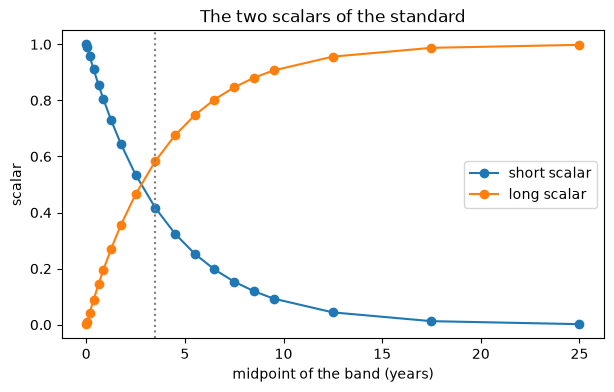

In [3]:
# The two scalars at the 19 midpoints, drawn, and their value at the 3.5-year point of the standard's example
alpha_short, alpha_long = shocks.shock_scalars(MID)
at_35 = shocks.shock_scalars(np.array([3.5]))
print("scalars at 3.5 years (short, long):", round(float(at_35[0][0]), 4), round(float(at_35[1][0]), 4))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(MID, alpha_short, marker="o", label="short scalar")
ax.plot(MID, alpha_long, marker="o", label="long scalar")
ax.axvline(3.5, color="grey", linestyle=":")
ax.set_xlabel("midpoint of the band (years)")
ax.set_ylabel("scalar")
ax.set_title("The two scalars of the standard")
ax.legend()
plt.show()

The short scalar starts at almost one in the overnight band and falls to nearly zero by 25 years; the long scalar is its mirror image, and the dotted line marks 3.5 years, where the short scalar is 0.4169 and the long one 0.5831, as the print above says. Because they always add up to one, a rotation that weights them differently can lower the short end and raise the long end without ever leaving the table of sizes. The picture shows the scalars only; the sizes that multiply them come in step 4, and a scalar of 0.9 at the short end is not a shock of 90 basis points.

### Step 2: the six shapes

With the three sizes of a currency, the parallel size $\bar S_{par}$, the short size $\bar S_{short}$ and the long size $\bar S_{long}$ (in basis points), the six shapes are (BCBS, SRP31.90 to SRP31.92; dossier 01, H.2):

$$\Delta S_{par}(t_k) = \pm \bar S_{par}, \qquad \Delta S_{short}(t_k) = \pm \bar S_{short}\, \alpha_{short}(t_k), \qquad \Delta S_{long}(t_k) = \pm \bar S_{long}\, \alpha_{long}(t_k)$$

$$\Delta S_{steep}(t_k) = -0.65\, |\Delta S_{short}(t_k)| + 0.9\, |\Delta S_{long}(t_k)|$$

$$\Delta S_{flat}(t_k) = +0.8\, |\Delta S_{short}(t_k)| - 0.6\, |\Delta S_{long}(t_k)|$$

The long shock is used only inside the two rotations: the engine's six scenario shapes are parallel up and down, short up and down, steepener and flattener. The steepener lowers the short end and raises the long end, the flattener does the reverse. The next cell works the standard's own example by hand at the 3.5-year midpoint with both the short and the long size at 100 bp, printing every intermediate, and then asks the engine for the same shapes with `shock_curve`. It is a check of the definition on one point, not a second implementation of the function; the engine remains the method.

In [4]:
# The worked example of SRP31.92 by hand at 3.5 years, and the engine's shape for each of the six shocks
t = np.array([3.5])
a_short, a_long = shocks.shock_scalars(t)
size = 100.0
short_abs, long_abs = size * a_short[0], size * a_long[0]
print("short scalar at 3.5 years:", round(float(a_short[0]), 4), "| long scalar:", round(float(a_long[0]), 4))
print("|short shock| =", round(float(short_abs), 2), "bp | |long shock| =", round(float(long_abs), 2), "bp")
steep_hand = -0.65 * short_abs + 0.9 * long_abs
flat_hand = 0.8 * short_abs - 0.6 * long_abs
by_hand = {"short-up": short_abs, "steepener": steep_hand, "flattener": flat_hand}
for shock in shocks.SHOCKS:
    value = float(shocks.shock_curve(shock, size, size, size, t)[0])
    hand = f" | by hand {by_hand[shock]:8.4f}" if shock in by_hand else ""
    print(f"{NAME[shock]:22s} engine {value:9.4f} bp{hand}")

short scalar at 3.5 years: 0.4169 | long scalar: 0.5831
|short shock| = 41.69 bp | |long shock| = 58.31 bp
parallel up            engine  100.0000 bp
parallel down          engine -100.0000 bp
steepener              engine   25.3864 bp | by hand  25.3864
flattener              engine   -1.6393 bp | by hand  -1.6393
short up               engine   41.6862 bp | by hand  41.6862
short down             engine  -41.6862 bp


### Step 3: the golden test of the standard's example

The standard prints its example with a rounded precision: 0.417, +41.7 bp, +25.4 bp and -1.6 bp. The engine holds those four values as a validation test, `irrbb.srp31_92_goldens`, that recomputes them and compares them with the printed ones within a tolerance of 0.0005 for the scalar and 0.05 bp for the shapes (a Contraste internal gate, not a regulatory one). The statistic is the largest absolute deviation. The next cell runs the test, prints each value beside its printed counterpart, and draws each deviation as a fraction of its tolerance.

test_id: irrbb.srp31_92_goldens | n = 4 | largest deviation: 0.0393
                 engine    printed    deviation
alpha_short      0.4169     0.4170       0.0001
short-up        41.6862    41.7000       0.0138
steepener       25.3864    25.4000       0.0136
flattener       -1.6393    -1.6000       0.0393
tolerances: {'tolerance_scalar': 0.0005, 'tolerance_bp': 0.05}


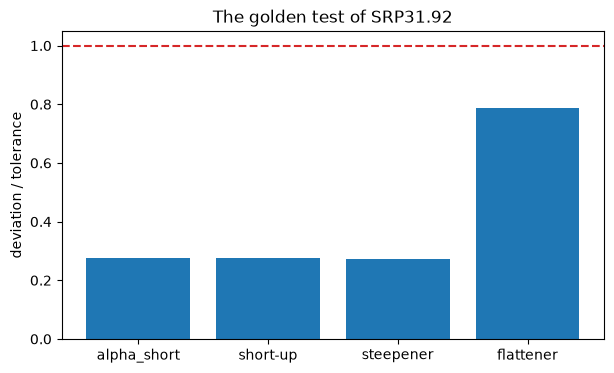

In [5]:
# Run the golden test of SRP31.92 and draw each deviation as a fraction of its tolerance
golden = rv_irrbb.srp31_92_goldens()
values, printed = golden.extras["values"], golden.extras["printed"]
dev, tol = golden.extras["deviations"], golden.extras["thresholds"]
print("test_id:", golden.test_id, "| n =", golden.n, "| largest deviation:", round(golden.statistic, 4))
print(f"{'':12s} {'engine':>10s} {'printed':>10s} {'deviation':>12s}")
for name in values:
    print(f"{name:12s} {values[name]:10.4f} {printed[name]:10.4f} {dev[name]:12.4f}")
print("tolerances:", tol)
limit = {n: tol["tolerance_scalar"] if n.startswith("alpha") else tol["tolerance_bp"] for n in values}
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(list(values), [dev[n] / limit[n] for n in values], color="tab:blue")
ax.axhline(1.0, color="tab:red", linestyle="--")
ax.set_ylabel("deviation / tolerance")
ax.set_title("The golden test of SRP31.92")
plt.show()

Every bar sits well under the red line at one, which is the tolerance of its own value: the largest, the flattener, uses about four fifths of the 0.05 bp it is allowed, and the scalar uses a fifth of 0.0005. The standard prints one decimal, so a flattener of -1.6393 against a printed -1.6 is a deviation of 0.0393 that is rounding and not error. The test therefore says "equal at the printed precision", which is what a golden test of a rounded source can say; it does not say the engine is right for other points or other sizes, which is what the next steps show on the bank's own currency.

### Step 4: the sizes by currency and calibration

The sizes are a table, not a formula. The Basel Committee calibrated them on historical changes of rates and published two tables: the 2016 one (BCBS d368, Annex 2, Table 1: data 2000 to 2015, 99th percentile of global factors, rounded to 50 bp) and the 2024 one that replaces it from 2026-01-01 (SRP31.90, Table 2, d578: data January 2000 to December 2023, 99.9th percentile of local six-month average absolute changes, rounded to 25 bp). The Chilean regulator publishes its own table in Annex 1 of RAN 21-13, which is the one the Chilean case uses. The engine holds the three as data: `shock_table` returns the sizes of a calibration as `{currency: (parallel, short, long)}`. The next cell prints three currencies in the two Basel calibrations, and the five rows of the Chilean table (a dash in the source is a missing value).

currencies in the 2016 and 2024 tables: 21 21
CLP in the 2024 table: no
rows of the Chilean table:
  canasta-1  (200.0, 300.0, 150.0)
  canasta-2  (400.0, 500.0, 300.0)
  CLP        (300.0, 400.0, 200.0)
  UR-nii     (300.0, None, None)
  UR-eve     (200.0, 250.0, 150.0)


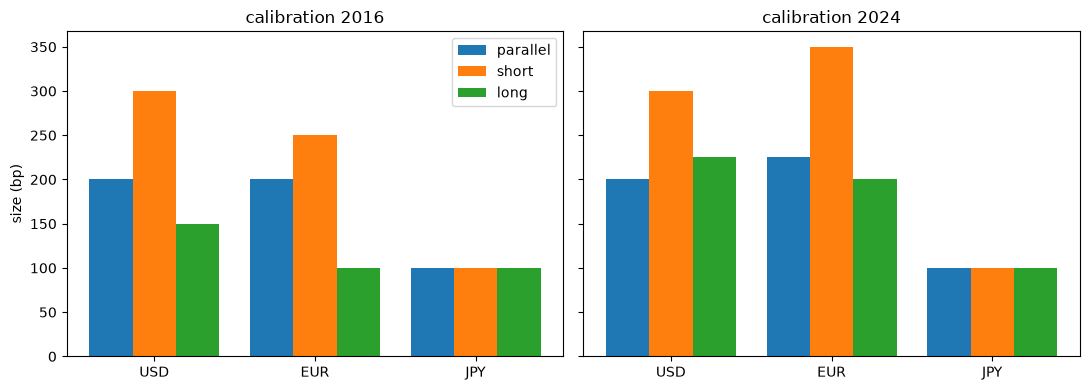

In [6]:
# Sizes in basis points of three currencies under the two Basel calibrations, and the rows of the Chilean table
t2016, t2024 = shocks.shock_table("2016"), shocks.shock_table("2024")
tcmf = shocks.shock_table("cmf-annex1")
currencies = ("USD", "EUR", "JPY")
has_clp = ("no", "yes")["CLP" in t2024]
print("currencies in the 2016 and 2024 tables:", len(t2016), len(t2024))
print("CLP in the 2024 table:", has_clp)
print("rows of the Chilean table:")
for row, sizes in tcmf.items():
    print(f"  {row:10s} {sizes}")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, table, year in zip(axes, (t2016, t2024), ("2016", "2024")):
    for j, kind in enumerate(("parallel", "short", "long")):
        ax.bar(np.arange(3) + 0.27 * (j - 1), [table[c][j] for c in currencies], 0.27, label=kind)
    ax.set_xticks(np.arange(3), currencies)
    ax.set_title("calibration " + year)
axes[0].set_ylabel("size (bp)")
axes[0].legend()
fig.tight_layout()
plt.show()

The two panels differ in the right place: for the dollar only the long bar grows between 2016 and 2024 (150 to 225 bp), for the euro all three grow, and for the yen none moves. Neither Basel table has the Chilean peso, which the print shows by its count of currencies and by the answer to the CLP question, and the Chilean regulator's table has its own rows, a basket-1 row of 200, 300 and 150 bp among them. What follows is that a size is a number with an owner: which table it came from decides the result as much as the shape does, and the figure shows only three of the twenty-one currencies.

What the engine does with a currency that has no entry is a design decision worth reading. `shock_size` returns the size of a currency with its **origin** (which table it came from). For a currency without an entry it **refuses**: a size is never invented. The caller may supply an estimate, but then the size carries the origin `contraste-estimate`, a bilingual label and the method, so no estimate can pass for a regulatory parameter; and a currency that has a tabled size refuses an estimate. The next cell shows the three cases: the peso in the Basel table (refused), the peso and the UF in the Chilean table (tabled; the UF takes the `UR-eve` row), and an illustration of the labelled estimate for the peso, which only shows the mechanism and is not used by the product.

In [7]:
# The size of a currency with its origin: refused without an entry, tabled in the Chilean table, and a labelled estimate
try:
    shocks.shock_size("CLP", "2024")
except ValueError as error:
    print("the engine refuses a size for CLP in the 2024 table:", type(error).__name__)
for currency in ("CLP", "CLF"):
    z = shocks.shock_size(currency, "cmf-annex1")
    print(f"{currency}: parallel, short, long = {z.parallel_bp:.0f}, {z.short_bp:.0f}, {z.long_bp:.0f} bp")
    print(f"  origin = {z.origin}")
label = {"en": "illustration only", "es": "illustration only"}
estimate = (300.0, 400.0, 200.0, label, "illustration of the labelled-estimate path")
z = shocks.shock_size("CLP", "2024", estimate=estimate)
print("labelled estimate: origin =", z.origin, "|", z.label[LANG])
used = [(u["currency"], u["parallel_bp"], u["short_bp"], u["long_bp"]) for u in out15["eve_shock_sizes"]]
print("sizes the Chilean case C15 reads for the EVE:", used)

the engine refuses a size for CLP in the 2024 table: ValueError
CLP: parallel, short, long = 300, 400, 200 bp
  origin = cmf-annex1
CLF: parallel, short, long = 200, 250, 150 bp
  origin = cmf-annex1
labelled estimate: origin = contraste-estimate | illustration only
sizes the Chilean case C15 reads for the EVE: [('CLP', 300.0, 400.0, 200.0), ('CLF', 200.0, 250.0, 150.0)]


### Step 5: the six shapes on the 19 midpoints

Now the six shapes for the USD under the 2024 calibration (200, 300 and 225 bp) at the 19 midpoints with `shock_curve`, drawn against the midpoints. The same cell then builds the steepener of the 2016 calibration (long size 150 bp instead of 225), to show how much the recalibration moves a rotation.

                           band 1     band 10     band 19
parallel up                200.00      200.00      200.00
parallel down             -200.00     -200.00     -200.00
steepener                 -194.72       36.80      201.73
flattener                  239.74       21.32     -134.28
short up                   299.79      125.06        0.58
short down                -299.79     -125.06       -0.58
steepener at band 19 with the 2016 sizes: 134.36 bp
2024 sizes: 201.73 bp


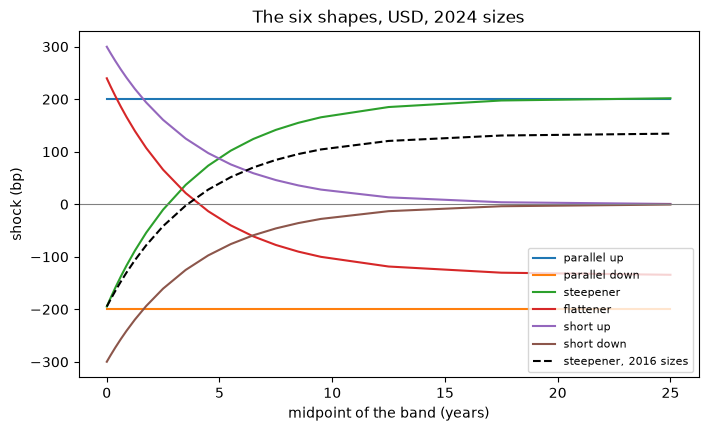

In [8]:
# The six shapes of the USD under the 2024 calibration at the 19 midpoints, and the steepener of the 2016 sizes
size24 = shocks.shock_size("USD", "2024")
size16 = shocks.shock_size("USD", "2016")
sizes24 = (size24.parallel_bp, size24.short_bp, size24.long_bp)
shapes = {s: shocks.shock_curve(s, *sizes24, MID) for s in shocks.SHOCKS}
steep16 = shocks.shock_curve("steepener", size16.parallel_bp, size16.short_bp, size16.long_bp, MID)
print(f"{'':22s} {'band 1':>10s} {'band 10':>11s} {'band 19':>11s}")
for s in shocks.SHOCKS:
    print(f"{NAME[s]:22s} {shapes[s][0]:10.2f} {shapes[s][9]:11.2f} {shapes[s][18]:11.2f}")
steep24 = shapes["steepener"][18]
print("steepener at band 19 with the 2016 sizes:", round(float(steep16[18]), 2), "bp")
print("2024 sizes:", round(float(steep24), 2), "bp")
fig, ax = plt.subplots(figsize=(8, 4.5))
for s in shocks.SHOCKS:
    ax.plot(MID, shapes[s], label=NAME[s])
ax.plot(MID, steep16, color="black", linestyle="--", label="steepener, 2016 sizes")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("midpoint of the band (years)")
ax.set_ylabel("shock (bp)")
ax.set_title("The six shapes, USD, 2024 sizes")
ax.legend(fontsize=8)
plt.show()

The short shocks fade with the horizon, from 300 bp overnight to almost nothing at 25 years; the parallel shocks stay flat at 200 bp; and the two rotations cross zero at different horizons. The steepener lowers the short end by almost the full 200 bp and lifts the long end past 200, and the dashed line shows how much of that long end comes from the recalibration: with the 2016 long size of 150 bp it reaches 134 bp at 25 years, with the 2024 size of 225 bp it reaches 202. The flattener is the mirror, large at the short end and negative at the long end. The picture shows one currency on one calibration and says nothing about which shape is the worst for a particular balance sheet, which depends on where its gaps are.

### Step 6: the post-shock floors

A large downward shock on a low rate would push it far below zero. The standard lets supervisors floor the post-shock rates at a level not above zero (SRP31.93), and the engine's `apply_floor` applies

$$r_{shocked} = \max\left(r_0 + \frac{s}{10^4},\ \min(f,\ r_0)\right)$$

where $s$ is the shock in basis points, $r_0$ the base rate and $f$ the floor: a floor never lifts a rate above its own pre-shock value, so a rate already below the floor keeps its value. The floor can be a number or one value per band. Besides the zero floor, the engine holds the maturity-dependent floor of the European Union, `eu_floor`: $-1.5\%$ at immediate maturity, rising 0.03 percentage points a year to zero at 50 years (Commission Delegated Regulation (EU) 2024/856, Article 3(7), as cited by the engine; dossier 01, H.5). The next cell applies the zero floor to the USD zero curve of 2022-06-30 under the parallel-down shock of 200 bp, then lists the bands where the floor binds under each of the six shocks.

  band    base rate    shocked, no floor     shocked, floor 0
     1      0.01279             -0.00721              0.00000
     2      0.01279             -0.00721              0.00000
     3      0.01678             -0.00322              0.00000
     4      0.02105              0.00105              0.00105
     5      0.02566              0.00566              0.00566
parallel up            bands where the zero floor binds: []
parallel down          bands where the zero floor binds: [1, 2, 3]
steepener              bands where the zero floor binds: [1, 2, 3]
flattener              bands where the zero floor binds: []
short up               bands where the zero floor binds: []
short down             bands where the zero floor binds: [1, 2, 3, 4]


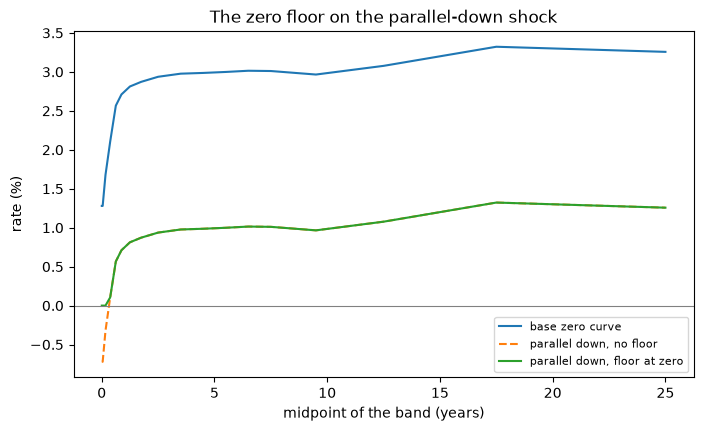

In [9]:
# Apply the zero floor to the parallel-down shock on the zero curve, then list where the floor binds under each shock
r0 = np.array(out14["curve"]["zero_rates_at_midpoints"])
floor = out14["scenarios"][0]["floor"]
raw = shocks.apply_floor(r0, shapes["parallel-down"], None)
floored = shocks.apply_floor(r0, shapes["parallel-down"], floor)
print(f"{'band':>6s} {'base rate':>12s} {'shocked, no floor':>20s} {'shocked, floor 0':>20s}")
for k in range(5):
    print(f"{k + 1:6d} {r0[k]:12.5f} {raw[k]:20.5f} {floored[k]:20.5f}")
for s in shocks.SHOCKS:
    gap = shocks.apply_floor(r0, shapes[s], floor) - shocks.apply_floor(r0, shapes[s], None)
    bound = [int(k) + 1 for k in np.flatnonzero(np.abs(gap) > 1e-12)]
    print(f"{NAME[s]:22s} bands where the zero floor binds: {bound}")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(MID, r0 * 100, label="base zero curve")
ax.plot(MID, raw * 100, linestyle="--", label="parallel down, no floor")
ax.plot(MID, floored * 100, label="parallel down, floor at zero")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("midpoint of the band (years)")
ax.set_ylabel("rate (%)")
ax.set_title("The zero floor on the parallel-down shock")
ax.legend(fontsize=8)
plt.show()

The base curve is the one of 2022-06-30, 1.28 percent in the first bands, so the 200 bp downward shock would take the short rates to about -0.72 percent; the solid line shows the floor bringing them back to zero for the first three bands, and from the fourth band on the curve is above the floor and the shock passes untouched. The list printed above shows the same logic for the other shocks: the floor binds only where a downward shape meets a low rate, never under the upward shapes. The picture shows one curve on one day; on a day with higher short rates the floor binds nowhere, and on a day with negative rates the rule that a floor never lifts a rate above its own level matters.

The same comparison with the maturity-dependent floor of the European Union. The next cell prints its value at some maturities and lists the bands where it would bind for each of the six shocks on the same curve. This is a what-if on the committed curve: the committed scenarios use the zero floor.

EU floor at 0, 1, 5, 10, 25, 50 and 60 years: [-0.015, -0.0147, -0.0135, -0.012, -0.0075, 0.0, 0.0]
parallel up            bands where the EU floor binds: []
parallel down          bands where the EU floor binds: []
steepener              bands where the EU floor binds: []
flattener              bands where the EU floor binds: []
short up               bands where the EU floor binds: []
short down             bands where the EU floor binds: [1, 2]


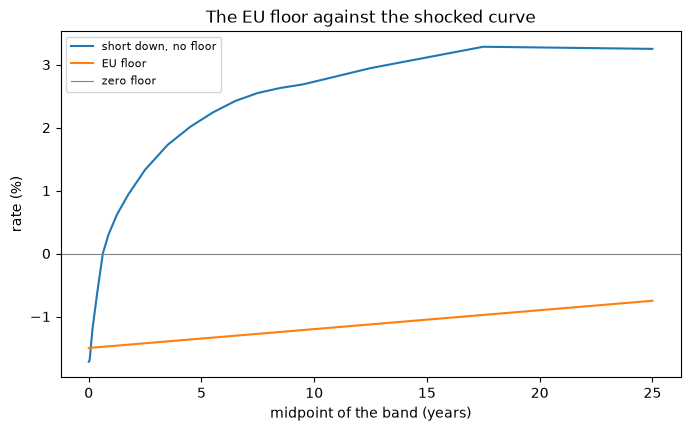

In [10]:
# The maturity-dependent floor of the European Union, and the bands where it binds under the six shocks
maturities = np.array([0.0, 1.0, 5.0, 10.0, 25.0, 50.0, 60.0])
print("EU floor at 0, 1, 5, 10, 25, 50 and 60 years:", [round(float(x), 4) for x in shocks.eu_floor(maturities)])
eu = shocks.eu_floor(MID)
for s in shocks.SHOCKS:
    gap = shocks.apply_floor(r0, shapes[s], eu) - shocks.apply_floor(r0, shapes[s], None)
    bound = [int(k) + 1 for k in np.flatnonzero(np.abs(gap) > 1e-12)]
    print(f"{NAME[s]:22s} bands where the EU floor binds: {bound}")
shocked = r0 + shapes["short-down"] / 1e4
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(MID, shocked * 100, label="short down, no floor")
ax.plot(MID, eu * 100, label="EU floor")
ax.axhline(0, color="grey", linewidth=0.8, label="zero floor")
ax.set_xlabel("midpoint of the band (years)")
ax.set_ylabel("rate (%)")
ax.set_title("The EU floor against the shocked curve")
ax.legend(fontsize=8)
plt.show()

The European floor starts at -1.5 percent overnight and rises to zero at 50 years, so it is far looser than the zero floor in the short bands: the short-down shock takes the first two bands to about -1.7 percent, below the -1.5 percent the floor allows, and these are the only two bands where it binds. The figure also shows why the maturity-dependent floor matters little for a dollar curve at these levels: from the third band on the shocked curve is above it. It is a what-if on the committed curve, since the committed scenarios use the zero floor; the figure does not say which floor a supervisor will require, only how much the choice changes the shocked curve.

## Results

**Answer:** the six shapes move the dollar curve very differently across the 19 bands, and the 2024 recalibration moved the rotations by raising one size. The steepener reaches +134.36 bp at the 25-year band with the 2016 sizes and +201.73 bp with the 2024 sizes, because the long size went from 150 to 225 bp. The zero floor then binds in bands 1 to 3 under the parallel-down shock, with the base rate of 0.01279 in band 1 taken from -0.00721 back to zero.

- **The scalars and the example.** At 3.5 years the short scalar is 0.4169 (the standard prints 0.417) and the long scalar 0.5831. With 100 bp sizes the short shock is 41.69 bp, the steepener +25.39 bp and the flattener -1.64 bp, each equal to the hand calculation of the definition. The golden test `irrbb.srp31_92_goldens` has deviations of 0.0001, 0.0138, 0.0136 and 0.0393 against the tolerances of 0.0005 and 0.05, a largest deviation of 0.0393; the flattener is the furthest from the printed value because the standard rounds to one decimal (-1.6393 against -1.6). The gate is therefore "equal at the printed precision", not "equal to the last digit".
- **The sizes.** For the USD only the long size moves between the calibrations (150 bp in 2016, 225 bp in 2024); for the EUR all three do (200/250/100 to 225/350/200); the JPY does not move. Both Basel tables have 21 currencies and neither has the peso, so the engine refuses a size for it instead of inventing one; the Chilean table gives the peso 300/400/200 bp and the UF 200/250/150 bp for the EVE. A validator should read the origin of every size before reading any result: it says whose number it is.
- **The shapes.** The steepener is the shape the recalibration moves most. The flattener, in contrast, is large at the short end (+239.74 bp in band 1) and negative at the long end (-134.28 bp in band 19), and the short shocks start at 299.79 bp overnight and fade to 0.58 bp.
- **The floors.** The zero floor binds in bands 1 to 3 under the parallel-down shock and the steepener, and in bands 1 to 4 under the short-down shock; it never binds under the upward shocks or the flattener. The maturity-dependent floor of the European Union starts at -0.015 and binds only under the short-down shock, in bands 1 and 2. The floor changes the shocked curve, so it changes every delta EVE that reads that curve.
- **What the notebook does not show.** How a shape reaches the cash flows to give a change in EVE (notebooks 03 and 06), the sizes of the NII shocks beyond the single parallel one, and the calibration of the sizes themselves, which the standard describes in SRP98 and the engine takes as data.

## Summary

- The six shapes come from two scalars, $e^{-t/4}$ and its complement, and three sizes per currency: the parallel and short shocks use one scalar each, and the steepener and the flattener rotate with the weights -0.65 and +0.9, and +0.8 and -0.6.
- The standard's own example, 0.417, +41.7 bp, +25.4 bp and -1.6 bp at 3.5 years, is a golden test of the engine, within its tolerance, and the flattener is the value furthest from the printed one.
- The sizes are a table: two Basel calibrations, 2016 and 2024, and the Chilean table. A currency without an entry is refused, and an estimate carries its label and method.
- A floor never lifts a rate above its pre-shock value; the zero floor binds in the short bands of the USD curve of mid-2022 under the downward shocks, and the maturity-dependent EU floor binds only under the short-down shock, in two bands.

**What to try next.** Change the long size of `shock_curve` and watch which of the two rotations moves more. Then continue with notebook 03, the behavioural layer.

## References

- BCBS, Standards: Interest rate risk in the banking book, SRP31.90 to SRP31.93 (the six shocks, the sizes and the floor) and SRP31.96 (the 19 time buckets). https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2016), d368, Standards: Interest rate risk in the banking book, Annex 2, Table 1 (the 2016 calibration). https://www.bis.org/bcbs/publ/d368.htm
- BCBS (2024), d578, Recalibration of shocks for interest rate risk in the banking book (the 2024 calibration, in force from 2026-01-01). https://www.bis.org/publications/202407-standards-recalibration-shocks-interest-rate-risk-banking-book.pdf
- CMF, Recopilacion Actualizada de Normas, chapter 21-13, Annex 1, sheet 9 (the Chilean shock sizes), as transcribed in the engine and in dossier 03, F.2.
- Commission Delegated Regulation (EU) 2024/856, Article 3(7) (the maturity-dependent floor), as cited by the engine. https://eur-lex.europa.eu/eli/reg_del/2024/856/oj/eng
- Dossier 01 of the Contraste research (Basel framework), section H.2 to H.3.